# Prepare the Data for Analysis

Turns per-event LIGO **LIV** MiniSEED downloads into a single combined file for the **sixdegrees** BRS pipeline (`01_brs_make_config` → `03_brs_analysis`). This notebook:

- Points at a dated download folder and lists rotation and translation channel SEED IDs (with `B` or `D` rate code)
- Loads rotation and translation `.ms` traces, applies instrument correction (sensitivity for tilt, velocity response for translation), and adds a zero **BJZ** dummy trace for rotation
- Rotates both sensor streams to a common **NEZ** frame using orientations from the StationXML inventory
- Merges rotation and translation into one stream (clears location codes) and optionally plots for a quick sanity check
- Writes `./output/event_<YYYYMMDD>/<YYYYMMDD>.mseed` for use as `path_to_mseed_file` in the event config

Set `date`, `path_to_data`, `code`, and `path_to_output` in the configuration cell before running the rest of the notebook.

This notebook is automated in: **02_brs_prepare_data.py**

In [1]:
import os
import obspy as obs

from sixdegrees.sixdegrees import sixdegrees
from obspy.signal.rotate import rotate2zne


### Configurations

In [12]:
# specify date
date = "2024-06-28"

# specify postfix of filename (e.g. "_L")
postfix = ""

# specify path to downloaded data
path_to_data = f"./data/downloads/miniseed_LIGO/{date}{postfix}/"

# specify path to stationxml file
stationxml = "./metadata/LIGO_HAN_LIV_AB.xml"

# specify channel code (D or B)
code = "D"

# specify seed names
rot_seed = [f"LI.LIV.IX.{code}JY", f"LI.LIV.IY.{code}JX"]
tra_seed = [f"LI.LIV.IX.{code}HZ", f"LI.LIV.IX.{code}HY", f"LI.LIV.IX.{code}HX"]

# specify path to output file
path_to_output = f"./output/event_{date.replace('-', '')}/"

### Load Metadata

In [13]:
inv = obs.read_inventory(stationxml)

### Load & Combine Waveform Data

Load all required streams as specified in the configuration file

In [14]:
# load rotation data
rot_st = obs.Stream()
for seed in rot_seed:
    filename = seed.replace(".", "_")+".ms"
    data_to_load = os.path.join(path_to_data, filename)
    try:
        rot_st += obs.read(data_to_load)
    except:
        if os.path.isfile(data_to_load):
            print(f"Error while loading!")
        else:
            print(f"File does not exist: {data_to_load}")

# remove instrument response
rot_st = rot_st.remove_sensitivity(inventory=inv)

# add dummy BJZ to rot_st
dummy = rot_st.select(station="LIV", channel="*JY").copy()
dummy[0].data = dummy[0].data * 0
dummy[0].stats.channel = "BJZ"
rot_st += dummy


In [15]:

# load translation data
tra_st = obs.Stream()
for seed in tra_seed:
    filename = seed.replace(".", "_")+".ms"
    data_to_load = os.path.join(path_to_data, filename)
    try:
        tra_st += obs.read(data_to_load)
    except:
        if os.path.isfile(data_to_load):
            print(f"Error while loading!")

# remove instrument response
tra_st = tra_st.remove_response(inventory=inv, output="VEL", taper=False, water_level=10)
# tra_st = tra_st.remove_sensitivity(inventory=inv)

### Rotate Data to ZNE

In [16]:
angles = {}
for _seed in rot_seed + tra_seed:
    angles[_seed] = inv.get_orientation(_seed)


In [ ]:
# rotate rotation data
Z, N, E = rotated_data = rotate2zne(
    rot_st.select(station="LIV", channel=f"*JZ")[0].data, 0, -90,
    rot_st.select(station="LIV", channel=f"*JY")[0].data, angles[f"LI.LIV.IX.{code}JY"]['azimuth'], angles[f"LI.LIV.IX.{code}JY"]['dip'],
    rot_st.select(station="LIV", channel=f"*JX")[0].data, angles[f"LI.LIV.IY.{code}JX"]['azimuth'], angles[f"LI.LIV.IY.{code}JX"]['dip'],
)


# ZYX > ZNE
rot_st.select(station="LIV", channel="*JY")[0].data = N
rot_st.select(station="LIV", channel="*JY")[0].stats.channel = code+"JN"
rot_st.select(station="LIV", channel="*JX")[0].data = E
rot_st.select(station="LIV", channel="*JX")[0].stats.channel = code+"JE"


# rotate translation data
Z, N, E = rotated_data = rotate2zne(
    tra_st.select(station="LIV", channel="*HZ")[0].data, angles[f"LI.LIV.IX.{code}HZ"]['azimuth'], angles[f"LI.LIV.IX.{code}HZ"]['dip'],
    tra_st.select(station="LIV", channel="*HY")[0].data, angles[f"LI.LIV.IX.{code}HY"]['azimuth'], angles[f"LI.LIV.IX.{code}HY"]['dip'],
    tra_st.select(station="LIV", channel="*HX")[0].data, angles[f"LI.LIV.IX.{code}HX"]['azimuth'], angles[f"LI.LIV.IX.{code}HX"]['dip'],
)


# ZYX > ZNE
tra_st.select(station="LIV", channel="*HY")[0].data = N
tra_st.select(station="LIV", channel="*HY")[0].stats.channel = code+"HN"
tra_st.select(station="LIV", channel="*HX")[0].data = E
tra_st.select(station="LIV", channel="*HX")[0].stats.channel = code+"HE"

del Z, N, E


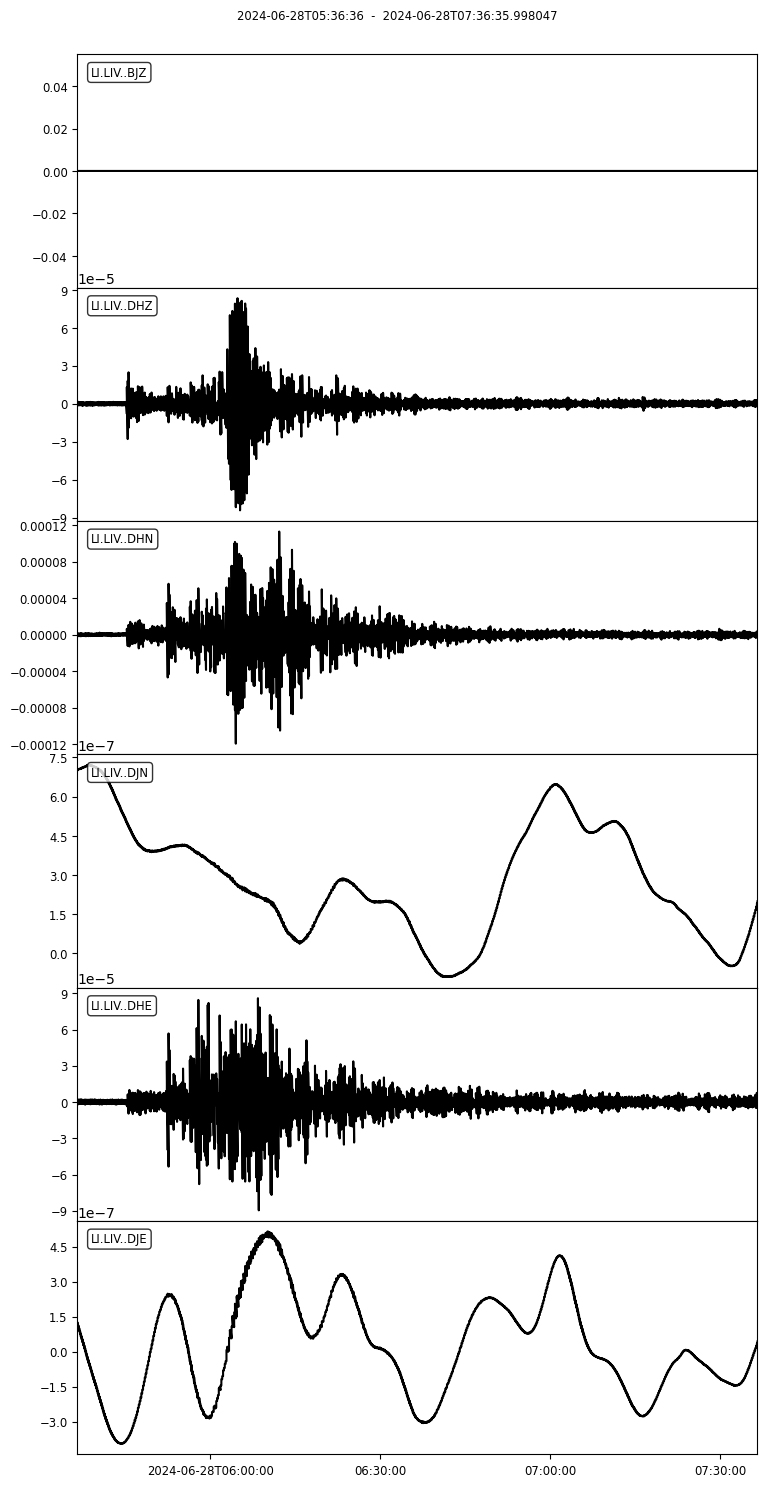

In [18]:
# combine data
st = obs.Stream()
st += rot_st
st += tra_st

# replace location code 
for tr in st:
    tr.stats.location = ""

# plot data
st.plot(equal_scale=False);

### Write Data

Write the data as one miniseed file for further processing

In [19]:
if not os.path.exists(path_to_output):
    os.makedirs(path_to_output)

In [20]:
print(f"writing data to {path_to_output}{date.replace('-', '')}.mseed")
st.write(path_to_output+f"{date.replace('-', '')}.mseed", format="MSEED")

writing data to ./output/event_20240628/20240628.mseed


/home/andbro/anaconda3/envs/sixdegrees/lib/python3.10/site-packages/obspy/io/mseed/core.py:773: UserWarning: The encoding specified in trace.stats.mseed.encoding does not match the dtype of the data.
A suitable encoding will be chosen.
  warnings.warn(msg, UserWarning)
/home/andbro/anaconda3/envs/sixdegrees/lib/python3.10/site-packages/obspy/io/mseed/core.py:824: UserWarning: File will be written with more than one different encodings.
This might have a negative influence on the compatibility with other programs.
  warnings.warn(msg % 'encodings')
